# Inference and model interpretation

A fitted boosting path supports several summaries of what the model did. This
page documents `summary()`, risk and selection plots, coefficient paths,
`varimp()`, partial effects, log-likelihood and AIC, bootstrap and REML
intervals for effects, residuals, and model comparison.

```{figure} ../figures/mermaid-a553f980afdf.svg
:name: mermaid-a553f980afdf
:alt: Branches from the boosting path to selection, coefficients, risk or AIC, and residuals, then to importance, summaries, stopping, and diagnostics.

A fitted boosting path supports selection, coefficient, risk, and residual summaries that feed interpretation, stopping, and diagnostic procedures.
```


In [1]:
import numpy as np
import polars as pl
import mboostrs as mb
from mboostrs.datasets import bodyfat

bf = bodyfat()
full_formula = (
    "DEXfat ~ age + waistcirc + hipcirc + elbowbreadth + kneebreadth + "
    "anthro3a + anthro3b + anthro3c + anthro4"
)
fit = mb.glmboost(
    full_formula,
    data=bf,
    family=mb.Gaussian(),
    control=mb.boost_control(200, 0.1),
)
fit

GLMBoostModel(formula='DEXfat ~ age + waistcirc + hipcirc + elbowbreadth + kneebreadth + anthro3a + anthro3b + anthro3c + anthro4', family=Gaussian, mstop=200)

## Summary

`summary()` reports the family and step length, the change in risk from the
offset-only model, and the base learners selected along the path. It prints as
fixed-width text and renders as a table in a notebook.

In [2]:
fit.summary()


Model,glmboost
Family,Gaussian
Response,DEXfat
Default predict scale,link (identity: same as response)
No. observations,71
Base learners,10
Learners selected,9
Iterations (mstop),200
Step length (nu),0.1000
Offset,30.7828
Risk at mstop,670.6114


The header carries the facts that fix what was fitted. `Risk at offset` is the
risk of the intercept-only model, which any fit has to improve on, and
`Risk reduction` is the fraction of the gap to zero that the path closed.

The coefficient table has no standard errors. Each coefficient is the sum of the shrunken updates the path applied to its
term, and the term entered the model on the same data that estimated it, so
the usual standard error would not have its stated coverage. The table instead reports `updates`, `% of path` and `first iter`: the number
and share of updates assigned to each term and when it first entered. A term
that entered late has received fewer updates and may remain more strongly
shrunk toward zero.

For a `gamboost`, a spline learner has no single coefficient, so the summary
reports the span of each learner's fitted effect instead, which is a
scalar comparable across learners of different kinds.

### Summary with cross-validation results

A fitted model carries no record of how its stopping iteration was chosen, so
the cross-validation block is only shown when the result is supplied. It puts
the iteration the model stopped at next to the one cross-validation prefers.

In [3]:
folds = mb.cv_weights(bf.height, type="kfold", B=10, seed=1)
cv = fit.cvrisk(folds=folds)
fit.summary(cv=cv)

Model,glmboost
Family,Gaussian
Response,DEXfat
Default predict scale,link (identity: same as response)
No. observations,71
Base learners,10
Learners selected,9
Iterations (mstop),200
Step length (nu),0.1000
Offset,30.7828
Risk at mstop,670.6114


The block reports both risks and the difference between them, and says whether
the model stops past or short of the optimum. The fold standard error helps interpret the risk difference. An excess risk
within one standard error indicates that a model 200 iterations past the
minimum has a similar estimated risk; a difference of several standard errors
indicates a larger discrepancy.

### Comparing summaries: `compare_summaries`

`compare_summaries` puts several models in one table, one column each. The
first block holds the scalar facts and the second the update counts per base
learner, with a blank where a learner is absent from a model's formula or was
never selected.

In [4]:
smooth_formula = " + ".join(
    f"bbs({name}, df=4)" for name in
    ["age", "waistcirc", "hipcirc", "elbowbreadth", "kneebreadth",
     "anthro3a", "anthro3b", "anthro3c", "anthro4"]
)
smooth = mb.gamboost(f"DEXfat ~ {smooth_formula}", data=bf,
                     family=mb.Gaussian(), control=mb.boost_control(200, 0.1))
cv_smooth = smooth.cvrisk(folds=folds)

mb.compare_summaries(fit, smooth, labels=["linear", "smooth"],
                     cv=[cv, cv_smooth])

Model comparison
==============================================================================
Models compared:          2   Observations:            71
Family:            Gaussian   Date:            2026-10-12
==============================================================================
Fit
                      linear    smooth
--------------------------------------
Model               glmboost  gamboost
Family              Gaussian  Gaussian
Base learners             10         9
Learners selected          9         9
Observations              71        71
Iterations (mstop)       200       200
Step length (nu)      0.1000    0.1000
Risk at mstop       670.6114  399.2723
Risk reduction         92.1%     95.3%
CV risk              13.3427   11.2168
CV optimal mstop         140        43
==============================================================================
Updates per base learner
learner       linear  smooth
----------------------------
kneebreadth       36      33
anthro3b          53       9
anthro3a           3      57
waistcirc         11      34
anthro4           42       1
elbowbreadth      25      13
anthro3c           6      29
hipcirc           10      19
age               14       5

Blank means the learner is not in that model's formula, or was never selected.
==============================================================================

The learner table reports each model's update allocation. Two models can have
similar risks while assigning very different shares of updates to the same
predictors; the table describes their fitted paths, not which predictors are
associated with the response.

Risks are comparable across columns only when the family and the data are the
same. Comparing a Gaussian risk with a Binomial one compares two different
losses, and `compare_summaries` states that in a note when the families
differ.

### Summary as a dictionary: `summary(as_dict=True)`

`summary(as_dict=True)` returns the same content as a JSON-serialisable
mapping, for logging a fit or comparing runs programmatically. Its keys are
stable across the rendered and dictionary summaries.

In [5]:
info = fit.summary(as_dict=True)
print(sorted(info))
print(f"\nmstop {info['mstop']}, risk {info['risk_at_mstop']:.4f}")

['family', 'formula', 'model_class', 'mstop', 'n', 'n_omitted', 'nonzero_coefficients', 'nu', 'offset', 'prediction_scale', 'risk_at_mstop', 'selection_frequency', 'weights']

mstop 200, risk 670.6114


## Risk and selection

Risk and selection plots are the first two summaries to inspect. They show how
far the fit travelled and which components were repeatedly chosen.

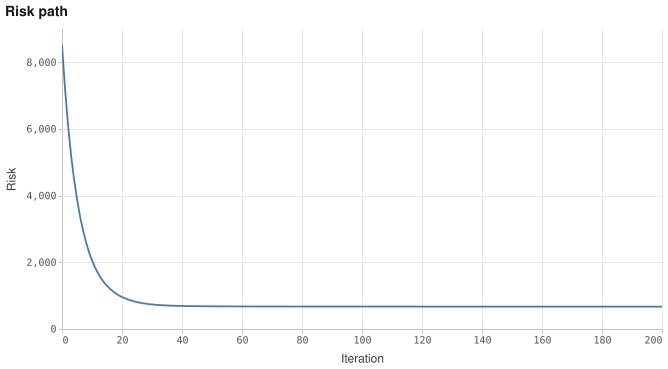

In [6]:
fit.plot_risk()

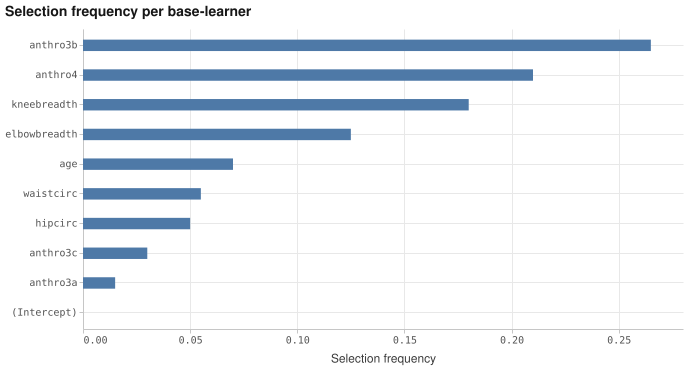

In [7]:
fit.plot_selected()

## Coefficient paths

For `glmboost`, `coef_path()` returns one coefficient trace per learner. The
path is more informative than the final coefficient alone: it shows
when a term entered and whether it kept accumulating updates.

In [8]:
path = fit.coef_path()
for name, vals in list(path.items())[:4]:
    print(f"{name}: final={vals[-1]:.3f}, first three={np.round(vals[:3], 3)}")

hipcirc: final=0.352, first three=[0.   0.09 0.09]
waistcirc: final=0.191, first three=[0.    0.    0.065]
anthro3a: final=3.327, first three=[0. 0. 0.]
anthro3b: final=3.942, first three=[0. 0. 0.]


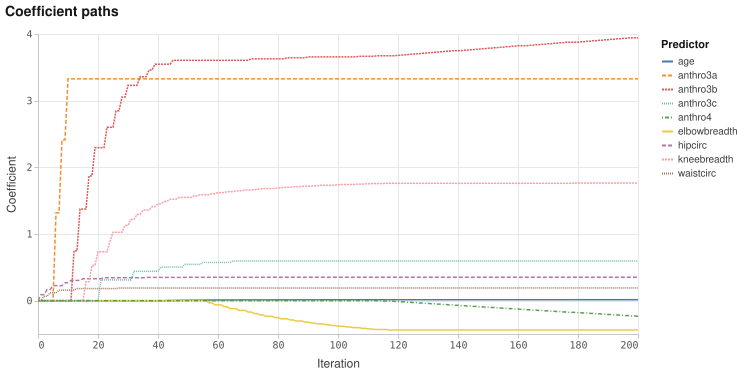

In [9]:
fit.plot_coef_path()

## Variable importance

`varimp()` attributes in-bag risk reduction to selected base learners.

In [10]:
fit.varimp()

{'reduction': {'(Intercept)': 0.0,
  'age': 0.000632789561274633,
  'waistcirc': 0.30684154829130333,
  'hipcirc': 0.43997965010956014,
  'elbowbreadth': 0.0003197405677977601,
  'kneebreadth': 0.03726071198475145,
  'anthro3a': 0.1426855966471975,
  'anthro3b': 0.06568695397348422,
  'anthro3c': 0.006502759403796301,
  'anthro4': 9.024946083476927e-05},
 'selfreq': {'(Intercept)': 0.0,
  'age': 0.07,
  'waistcirc': 0.055,
  'hipcirc': 0.05,
  'elbowbreadth': 0.125,
  'kneebreadth': 0.18,
  'anthro3a': 0.015,
  'anthro3b': 0.265,
  'anthro3c': 0.03,
  'anthro4': 0.21}}

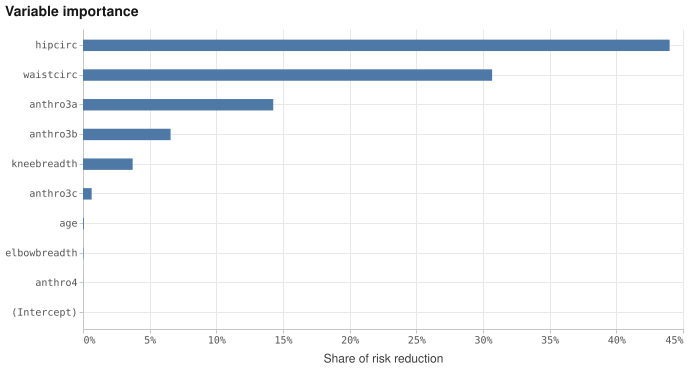

In [11]:
fit.plot_varimp()

## Partial effects

For `gamboost`, coefficients are often basis coefficients. Use
`partial_effects()` or `plot_partial_effects()` to see the effect on the
predictor scale.

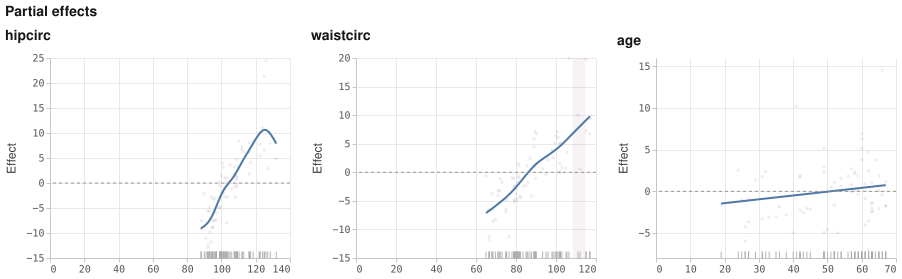

In [12]:
fit_gam = mb.gamboost(
    "DEXfat ~ bbs(waistcirc, df=4) + bbs(hipcirc, df=4) + bols(age)",
    data=bf,
    family=mb.Gaussian(),
    control=mb.boost_control(200, 0.1),
)
fit_gam.plot_partial_effects()

In [13]:
waist, effect = fit_gam.partial_effects(which="waistcirc")["waistcirc"]
print(f"waist effect range: {effect.min():.2f} to {effect.max():.2f}")

waist effect range: -7.12 to 9.79


## Log-likelihood and AIC

Likelihood-based summaries are available for likelihood families. The AIC path
is indexed by boosting iteration; `aic.mstop` is the selected iteration, so the
corresponding array entry is `aic.aic[aic.mstop - 1]`.

In [14]:
aic = fit.aic()
idx = max(aic.mstop - 1, 0)
print("logLik:", round(float(fit.logLik()), 2))
print(f"AIC-optimal mstop: {aic.mstop}; AIC={aic.aic[idx]:.1f}")

logLik: -180.46
AIC-optimal mstop: 45; AIC=3.4


## Confidence intervals for effects

`confint()` uses a bootstrap to produce pointwise intervals for learner effects.
These are post-selection summaries of the chosen fit; they do not
constitute selective inference on the selection path.

In [15]:
ci = fit.confint("waistcirc", B=50, seed=0)
ci

/tmp/ipykernel_67892/1982752506.py:1: UserWarning: Bootstrap intervals for boosted coefficients can under-cover: shrinkage and selection bias remain in the replicated fits. For gamboost fits, confint(method='refit') provides conditional REML-refit partial-effect intervals.
  ci = fit.confint("waistcirc", B=50, seed=0)
/Users/fcela/src/public_github/mboostrs/python/mboostrs/glmboost.py:863: UserWarning: optimal mstop 200 is within 5% of the search cap 200; the search range was exhausted — consider increasing mstop and re-running cvrisk.
  result = CvRiskResult(


{'lower': {'waistcirc': np.float64(0.0823971699189951)},
 'upper': {'waistcirc': np.float64(0.29558216311895247)},
 'level': 0.95,
 'boot_coefs': array([[0.17213525],
        [0.28627335],
        [0.15061122],
        [0.02362216],
        [0.26068213],
        [0.12895345],
        [0.23852816],
        [0.13887923],
        [0.18014145],
        [0.21920787],
        [0.24236896],
        [0.24195863],
        [0.28761269],
        [0.23423631],
        [0.28249035],
        [0.17504278],
        [0.14466266],
        [0.16233004],
        [0.13834326],
        [0.16965412],
        [0.34795913],
        [0.26508822],
        [0.08199217],
        [0.15369895],
        [0.20413001],
        [0.18624416],
        [0.29789588],
        [0.17090933],
        [0.17569697],
        [0.21529723],
        [0.21667223],
        [0.16420079],
        [0.09984749],
        [0.16406285],
        [0.08379215],
        [0.2214565 ],
        [0.13632858],
        [0.11390066],
        [0.13652233

/Users/fcela/src/public_github/mboostrs/python/mboostrs/plot.py:1601: UserWarning: Bootstrap intervals for boosted coefficients can under-cover: shrinkage and selection bias remain in the replicated fits. For gamboost fits, confint(method='refit') provides conditional REML-refit partial-effect intervals.
  ci = model.confint(parm=parm, level=level, B=B, seed=seed)


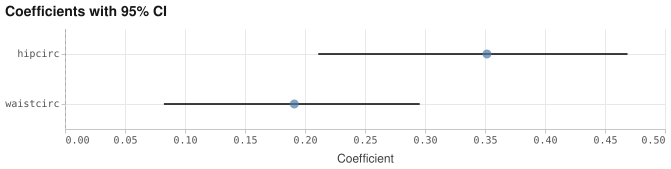

In [16]:
mb.plot.plot_confint(fit, parm=["waistcirc", "hipcirc"], B=50, seed=0)

### Intervals from a REML refit: `gam_refit`

The bootstrap interval describes variation in the boosted estimate across
resamples. Early stopping shrinks each estimate toward zero, so the band is
centered on a shrunken curve and may undercover the true effect; on the
simulated additive task of [](../cases/benchmark_insight.ipynb) a nominal 90%
band covered 62%. `mb.gam_refit(model)` refits the selected terms as one
penalized regression with REML smoothing parameters, as mgcv does, and gives
intervals from the coefficient covariance; on the same task its nominal 90%
bands covered 91%. The next cell refits the model above. Its arguments,
supported terms and families, corrected intervals, random effects and the R
equivalent are documented in [](refit.ipynb); the derivation is in
[](../methodology/penalized_reml.ipynb).

In [17]:
refit = mb.gam_refit(fit_gam)
estimate, lower, upper = refit.effects(bf, level=0.9)["bbs(waistcirc, df=4)"]
{"effective df": {term: round(edf, 2) for term, edf in refit.edf.items()},
 "sigma": round(refit.sigma, 3),
 "mean 90% band width, waistcirc": round(float(np.mean(upper - lower)), 3)}

{'effective df': {'bbs(waistcirc, df=4)': 1.0,
  'bbs(hipcirc, df=4)': 1.75,
  'bols(age)': 1.0},
 'sigma': 3.999,
 'mean 90% band width, waistcirc': 2.734}

`edf` is each term's effective degrees of freedom after REML smoothing: a
value near 1 means the data support a straight line, larger values a curve.
The boosted fit gave every smooth the same four degrees of freedom per step;
REML estimates a separate smoothing parameter for each term.

## Residuals

Residuals are available as arrays and as diagnostic tables. Use
[](diagnostics.ipynb) for the full workflow.

In [18]:
res = fit.residuals()
print(f"Residual range: {res.min():.2f} to {res.max():.2f}")

Residual range: -6.97 to 11.05


In [19]:
mb.residual_frame(fit, kind="pearson").head()

index,y,fitted,residual_kind,residual
i64,f64,f64,str,f64
0,41.68,40.184267,"""pearson""",1.495733
1,43.29,42.035941,"""pearson""",1.254059
2,35.41,36.038627,"""pearson""",-0.628627
3,22.79,26.094193,"""pearson""",-3.304193
4,36.42,33.416391,"""pearson""",3.003609


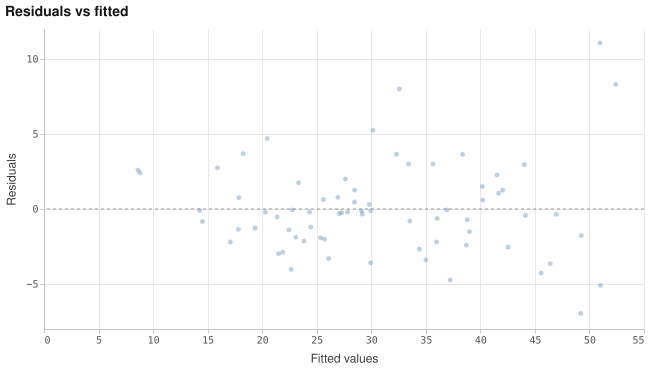

In [20]:
fit.plot_residuals()

## Model comparison

Compare models at their selected path positions. For AIC arrays, use
`mstop - 1` to read the selected iteration.

In [21]:
reduced = mb.glmboost(
    "DEXfat ~ waistcirc + hipcirc + age",
    data=bf,
    family=mb.Gaussian(),
    control=mb.boost_control(200, 0.1),
)
aic1 = fit.aic()
aic2 = reduced.aic()
idx1 = max(aic1.mstop - 1, 0)
idx2 = max(aic2.mstop - 1, 0)
print(f"Full model AIC:    {aic1.aic[idx1]:.1f} at mstop={aic1.mstop}")
print(f"Reduced model AIC: {aic2.aic[idx2]:.1f} at mstop={aic2.mstop}")

Full model AIC:    3.4 at mstop=45
Reduced model AIC: 3.8 at mstop=49


In [22]:
mb.compare_models(fit, reduced, labels=["full", "reduced"], output="auto")

label,risk,logLik,GAIC,mstop,selected_learners,criterion,normalization,df_convention,df,penalty
str,f64,f64,f64,i64,f64,str,str,str,f64,null
"""full""",684.332306,-181.179249,3.352738,45,9.0,"""mboost_corrected""","""per_observation""","""conditional_hat_trace""",1.917234,null
"""reduced""",1099.22245,-198.003221,3.82548,49,3.0,"""mboost_corrected""","""per_observation""","""conditional_hat_trace""",1.879522,null


## See also

- [](diagnostics.ipynb) for residuals, calibration, intervals, and LSS diagnostics.
- [](glmboost.ipynb) for linear boosting with coefficient paths.
- [](gamboost.ipynb) for additive partial effects.
- [](model_selection.ipynb) for cross-validated `mstop`.
- [](plotting_serialization.ipynb) for all plotting functions.